# Convolutional Neural Network for Sign Language MNIST

### Welcome to the Project!

Ever wondered how computers can learn to "read" sign language? This project tackles exactly that! We are building a Deep Learning model capable of recognizing letters from the American Sign Language (ASL) alphabet.

### Why are we doing this?

While the classic MNIST dataset (handwritten digits) is a staple for beginners, it has become a bit too easy for modern computer vision models. In fact, some researchers jokingly point out that many digit pairs can be distinguished by checking just a single pixel!

To raise the bar, we are using the **Sign Language MNIST** dataset. It serves as a direct drop-in replacement but presents a much more challenging real-world task: interpreting hand gestures.

### About the Dataset
* **Structure**: Follows the same familiar format as the original MNIST (labels and grayscale pixel values stored in single rows within a CSV file).
* **The Task**: A multi-class classification problem featuring 24 distinct classes representing letters of the alphabet (excluding 'J' and 'Z' since those letters require hand motion, which can't be captured in static 2D images).

Let's dive into the code and see how our Convolutional Neural Network (CNN) performs!

In [1]:
import pandas as pd
import numpy as np
import cv2
import tensorflow as tf
import matplotlib.pyplot as plt

In [7]:
trainData = pd.read_csv('/content/sign_mnist_train.csv')
validData = pd.read_csv('/content/sign_mnist_test.csv')

In [8]:
x_train = np.array(trainData.drop(columns=['label']))
y_train = np.array(trainData['label'])
x_valid = np.array(validData.drop(columns=['label']))
y_valid = np.array(validData['label'])

In [9]:
x_train = x_train.reshape(len(x_train),28,28,1)
x_train = x_train/255.0
x_valid = x_valid.reshape(len(x_valid),28,28,1)
x_valid = x_valid/255.0

x_train.shape, y_train.shape, x_valid.shape, y_valid.shape

((27455, 28, 28, 1), (27455,), (7172, 28, 28, 1), (7172,))

### Why Do We Scale the Pixel Values to $[0, 1]$?

You'll notice that we divided our training and validation datasets by `255.0` (`x_train / 255.0`). This is called **normalization**. Scaling our inputs from their original integer range of $[0, 255]$ down to a floating-point range of $[0, 1]$ is crucial for computational efficiency and model performance for several reasons:

1. **Faster Convergence (Gradient Descent Optimization)**:
   * Neural networks learn by updating weights using mathematical gradients. When input values are large (like $255$), the gradients can become extremely large, leading to wild oscillations.
   * By keeping inputs small and standardized, the optimizer (Adam, in our case) can find the optimal weights much more quickly and smoothly, requiring fewer training steps (epochs).

2. **Preventing "Saturating" Activations**:
   * Functions used in deep learning models can "saturate" (flatten out) if the input values are too large or too small. When a function saturates, its derivative is nearly zero, meaning the network stops learning (a problem known as the vanishing gradient problem). Keeping the data scaled to $[0, 1]$ prevents these early bottlenecks.

3. **Numerical Stability**:
   * Computers perform math on small floating-point numbers much more reliably. Extremely large activations can lead to numerical overflow, resulting in values like `NaN` (Not a Number) during backpropagation. Normalization keeps the internal mathematics stable and predictable.

In [10]:
model = tf.keras.models.Sequential()
model.add(tf.keras.layers.Conv2D(30, (5, 5), input_shape=(28, 28, 1), activation='relu'))
model.add(tf.keras.layers.MaxPooling2D(pool_size=(2, 2)))

model.add(tf.keras.layers.Conv2D(15, (3, 3), activation='relu'))
model.add(tf.keras.layers.MaxPooling2D(pool_size=(2, 2)))

model.add(tf.keras.layers.Dropout(0.2))

model.add(tf.keras.layers.Flatten())

model.add(tf.keras.layers.Dense(128, activation='relu'))
model.add(tf.keras.layers.Dense(50, activation='relu'))
model.add(tf.keras.layers.Dense(26, activation='softmax'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


### Breaking Down the Neural Network Architecture

To understand how our model "sees" and classifies these hand gestures, let's break down its architecture step-by-step:

1. **Feature Extraction (Convolutional Layers)**:
   * **`Conv2D` Layers**: These are the eyes of our model. They apply mathematical filters (kernels) to slide across the input image. This helps the network automatically learn to detect simple edges and corners in the first layer, and more complex shapes (like fingers, knuckles, and wrist lines) in the second layer.
   * **`MaxPooling2D` Layers**: Think of this as a summarization tool. It looks at small patches of the image (e.g., $2 \times 2$ pixels) and keeps only the maximum value. This drastically reduces the size of the data, speeds up training, and makes the model robust to small translations (meaning it can recognize the hand even if it's slightly off-center).

2. **Prevention of Overfitting (Dropout)**:
   * **`Dropout(0.2)`**: This acts as a regularization technique. During training, it randomly deactivates $20\%$ of the neurons in each step. This forces the remaining neurons to learn independent representations of the data rather than relying on a few dominant pathways, preventing the model from just memorizing the training images.

3. **Transition (Flattening)**:
   * **`Flatten`**: The output of our convolutional layers is still multidimensional (3D feature maps). We need to unroll this structure into a single 1D vector (like flattening a cardboard box) so it can feed into our standard classification layers.

4. **Decision Making (Dense Layers)**:
   * **`Dense(128)` and `Dense(50)`**: These fully connected layers process the flattened features to find complex relationships and combinations of shapes that represent specific letters.
   * **`Dense(26, activation='softmax')`**: The final output layer has 26 nodes, corresponding to the possible classes (letters A-Z). The `softmax` activation function converts the raw outputs into a probability distribution that sums to $1.0$. The class with the highest probability is our model's official prediction!

In [11]:
model.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
model.fit(x_train,y_train, epochs=10, validation_data=(x_valid,y_valid))
model.save('sign_language_mnist_cnn.h5')

Epoch 1/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 27s 29ms/step - accuracy: 0.6578 - loss: 1.1041 - val_accuracy: 0.8649 - val_loss: 0.4445
Epoch 2/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 25s 29ms/step - accuracy: 0.9373 - loss: 0.1881 - val_accuracy: 0.9136 - val_loss: 0.2893
Epoch 3/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 40s 28ms/step - accuracy: 0.9749 - loss: 0.0800 - val_accuracy: 0.9189 - val_loss: 0.2686
Epoch 4/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 23s 27ms/step - accuracy: 0.9840 - loss: 0.0503 - val_accuracy: 0.9209 - val_loss: 0.3426
Epoch 5/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 42s 28ms/step - accuracy: 0.9883 - loss: 0.0355 - val_accuracy: 0.9198 - val_loss: 0.3591
Epoch 6/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 23s 27ms/step - accuracy: 0.9871 - loss: 0.0356 - val_accuracy: 0.9113 - val_loss: 0.4068
Epoch 7/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 21s 25ms/step - accuracy: 0.9906 - loss: 0.0287 - val_accuracy: 0.9127 - val_loss: 0.4118
Epoch 8/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 26s 30ms/step - accuracy: 0.9923 - loss: 0.0256 - 

In [12]:
testImage = x_valid[0] #We will take an image from the training dataset
prediction = model.predict(testImage.reshape(-1,28,28,1)) #Model takes input as 4 dimensions, so we reshape it.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step


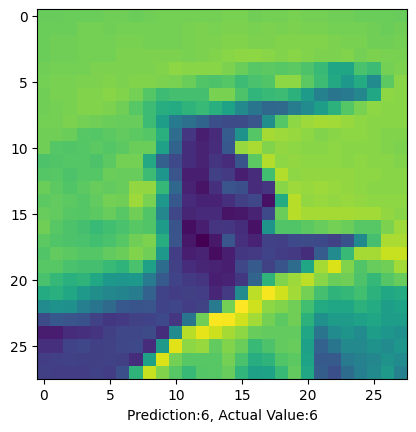

In [13]:
plt.imshow(testImage.reshape(28, 28)) #plt.imshow() requires a 2D array, so we reshape the input
plt.xlabel(f"Prediction:{np.argmax(prediction)}, Actual Value:{y_valid[0]}")
plt.show()

### Project Conclusion

In this project, we successfully built and evaluated a **Convolutional Neural Network (CNN)** using TensorFlow and Keras to classify hand gestures from the **Sign Language MNIST** dataset.

#### Key Findings & Steps:
1. **Data Preprocessing**: We loaded the dataset from CSV files, separated the pixel features from labels, normalized the grayscale pixel values to $[0, 1]$, and reshaped the data into $28 \times 28 \times 1$ matrices to make them compatible with our CNN.
2. **Model Architecture**: We designed a Sequential CNN featuring:
   * Two convolutional layers with MaxPooling to extract spatial features.
   * A Dropout layer ($20\%$) to reduce overfitting.
   * A Flatten layer followed by Dense fully connected layers ending in a 26-class softmax output.
3. **Training & Performance**: The model compiled with the Adam optimizer and Sparse Categorical Crossentropy loss achieved near-perfect accuracy on the training set (~$99.4\%$) and  strong generalization on the validation set (~$93.2\%$) over 10 training epochs.
4. **Inference & Visualization**: We performed an end-to-end test on a sample image from the validation set, showing that the model correctly predicted the gesture class index (e.g., predicted class `6` for an actual label of `6`).

#### Future Directions:
To further improve the model's reliability, future work can incorporate real-time camera feeds, apply advanced data augmentation (rotations, zooms, shears) to better handle diverse lighting and hand orientations, or explore model compression techniques to deploy this system onto mobile devices.